# Tutorial 2: Aligning spatial transcriptomics slices of mouse olfactory bulb

## Data Preparation

Please download the required data files from the provided link:
[Download here](https://pan.baidu.com/s/17K1cmxOPmhSvV6dG6gnafw?pwd=sjbx)

- `10X.h5ad`
- `Stereo.h5ad`

After downloading, place both files into the `datasets` folder located in the same directory as this notebook.

The folder structure should be organized as follows:

```
project_root/
│
├── datasets/
│   └── MOB/
│       ├── 10X.h5ad
│       └── Stereo.h5ad
│
├── Tutorial2_Aligning_spatial_transcriptomics_slices_of_mouse_olfactory_bulb.ipynb
│
└── SpaMOMA/
```

## import packages

In [1]:
from SpaMOMA.SpaMOMA import SpaMOMA

site-packages/torch/cuda/__init__.py:63: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


2026-11-22 22:43:15.494395: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-22 22:43:15.539077: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-22 22:43:15.539123: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-22 22:43:15.539156: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-22 22:43:15.548754: I tensorflow/core/platform/cpu_feature_g

2026-11-22 22:43:17.129064: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


## Specify Slice Metadata

In [2]:
save_directory = "./SpaMOMA_output/MOB/"  
spamoma = SpaMOMA(save_dir=save_directory)
spamoma.add_slice(
    sample_id="10X",  
    raw_data_path="./datasets/MOB/10X.h5ad",  
    feature="rna"  
)
spamoma.add_slice(
    sample_id="Stereo", 
    raw_data_path="./datasets/MOB/Stereo.h5ad", 
    feature="rna"  
)
spamoma.set_reference('10X')
print(f"aligning {[sid for sid in spamoma.input_slice_dict.keys() if sid != spamoma.reference_sample_id]} to {spamoma.reference_sample_id}")

aligning ['Stereo'] to 10X


## Data Preprocessing

preprocessing rna features...


------Calculating spatial graph...
The graph contains 8295 edges, 1185 cells.
7.0000 neighbors per cell on average.


Size of Input:  (1185, 3000)


2026-11-22 22:01:41.166614: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1886] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 50548 MB memory:  -> device: 0, name: NVIDIA A100 80GB PCIe, pci bus id: 0000:17:00.0, compute capability: 8.0
2026-11-22 22:01:41.172407: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:382] MLIR V1 optimization pass is not enabled


2026-11-22 22:01:41.455758: I tensorflow/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


preprocessing rna features...


------Calculating spatial graph...


The graph contains 61789 edges, 8827 cells.
7.0000 neighbors per cell on average.
Size of Input:  (8827, 3000)


2026-11-22 22:01:59.840032: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1886] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 50548 MB memory:  -> device: 0, name: NVIDIA A100 80GB PCIe, pci bus id: 0000:17:00.0, compute capability: 8.0


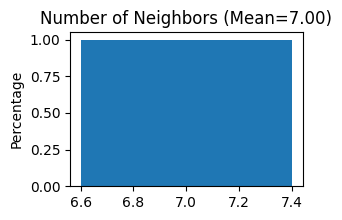

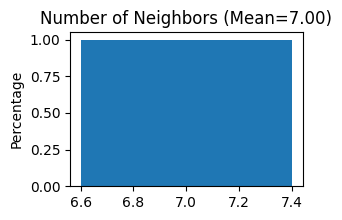

In [3]:
spamoma.preprocess_input_slices()

## Generate Spatial Pattern Images

generating spatial pattern image... gaussian_sigma:1.0, interpolation_method:linear, max_distance_ratio"1.2


saving image...


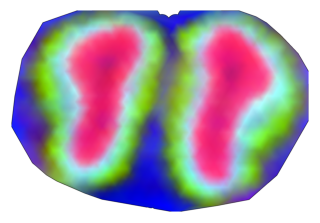

Img for 10X is saved to ./SpaMOMA_output/MOB/10X/RGB.png
generating spatial pattern image... gaussian_sigma:1.0, interpolation_method:linear, max_distance_ratio"1.2


saving image...


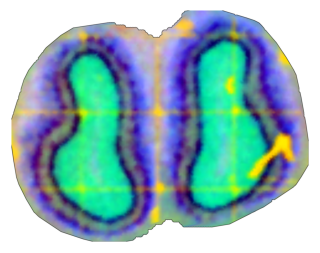

Img for Stereo is saved to ./SpaMOMA_output/MOB/Stereo/RGB.png


In [4]:
spamoma.generate_imgs()

In [5]:
spamoma.input_slice_dict

{'10X': {'sample_id': '10X',
  'raw_data_path': './datasets/MOB/10X.h5ad',
  'feature': 'rna',
  'pseudo_color_key': 'pca',
  'processed_data': AnnData object with n_obs × n_vars = 1185 × 3000
      obs: 'orig.ident', 'nCount_Spatial', 'nFeature_Spatial', 'X', 'celltype', 'batch', 'row', 'col', 'x', 'y', 'imagerow', 'imagecol', 'img_x', 'img_y', 'spot_x', 'spot_y', 'mclust', 'my_pixel_x', 'my_pixel_y'
      var: 'features', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
      uns: 'Spatial_Net', 'hvg', 'log1p', 'mclust_colors', 'neighbors', 'umap', 'spatial_neighbors', 'moranI'
      obsm: 'STAGATE', 'X_umap', 'spatial', 'pca'
      obsp: 'connectivities', 'distances', 'spatial_connectivities', 'spatial_distances',
  'SPI_path': './SpaMOMA_output/MOB/10X/RGB.png'},
 'Stereo': {'sample_id': 'Stereo',
  'raw_data_path': './datasets/MOB/Stereo.h5ad',
  'feature': 'rna',
  'pseudo_color_key': 'pca',
  'processed_data': AnnData object with n_obs × n_vars =

## Model Training

In [6]:
spamoma.train(coarse_epochs=100, fine_epochs=120)

{'status': 'completed',
 'run_id': '20261122-220411-04a87f85',
 'run_dir': './SpaMOMA_output/MOB/runs/20261122-220411-04a87f85',
 'execution_mode': 'sequential',
 'stages': {'coarse': {'best_path': './SpaMOMA_output/MOB/runs/20261122-220411-04a87f85/coarse_model/best.pth',
   'last_path': './SpaMOMA_output/MOB/runs/20261122-220411-04a87f85/coarse_model/last.pth',
   'resume_path': './SpaMOMA_output/MOB/runs/20261122-220411-04a87f85/coarse_model/resume.pt',
   'history_path': './SpaMOMA_output/MOB/runs/20261122-220411-04a87f85/coarse_model/history.jsonl',
   'global_step': 330,
   'best_metric': 153.02976321343334,
   'best_epoch': 100,
   'optimizer_steps': 330,
   'attempted_steps': 330,
   'skipped_updates': 0,
   'selected_pretrained': False,
   'baseline_preservation': {'epe_px': 98.49697301503048,
    'pck_1px': 0.31961743037431034,
    'pck_3px': 0.401842054341311,
    'valid_fraction': 0.6756473214285714,
    'metric_scope': 'held_out_synthetic_transforms',
    'white_augmentati

## Slice Alignment

coarse checkpoint: ./SpaMOMA_output/MOB/runs/20261122-220411-04a87f85/coarse_model/last.pth


fine checkpoint: ./SpaMOMA_output/MOB/runs/20261122-220411-04a87f85/fine_model/last.pth


aligned 10X adata is saved to: ./SpaMOMA_output/MOB//alignment_output/10X.h5ad


****************** aligning Stereo to 10X ..... ******************
Loading RoMa: ./SpaMOMA_output/MOB/runs/20261122-220411-04a87f85/coarse_model/last.pth; DINO: check_points/dinov2_vitl14_pretrain.pth; resolution: (560, 560)


Loading RoMa: ./SpaMOMA_output/MOB/runs/20261122-220411-04a87f85/fine_model/last.pth; DINO: check_points/dinov2_vitl14_pretrain.pth; resolution: (560, 560)


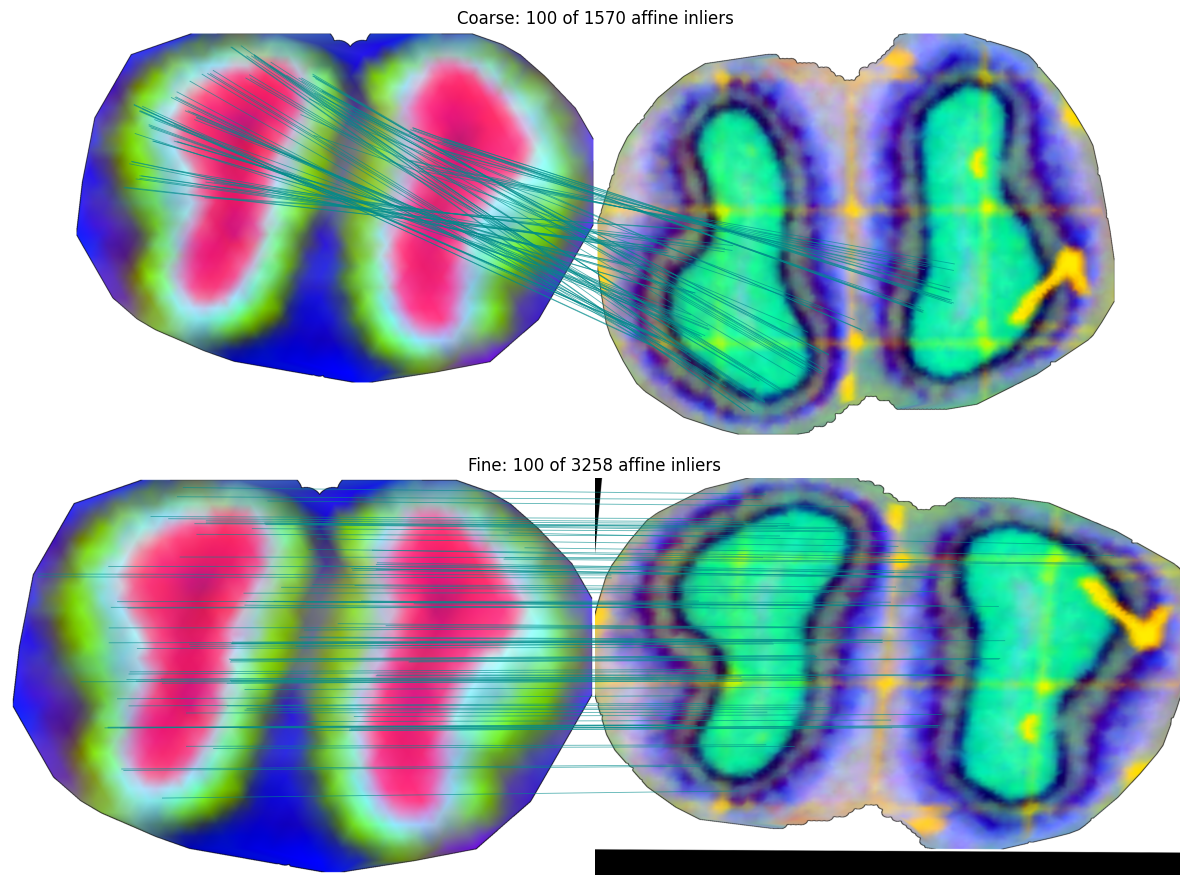

aligned Stereo adata is saved to: ./SpaMOMA_output/MOB//alignment_output/Stereo.h5ad
fine alignment done!


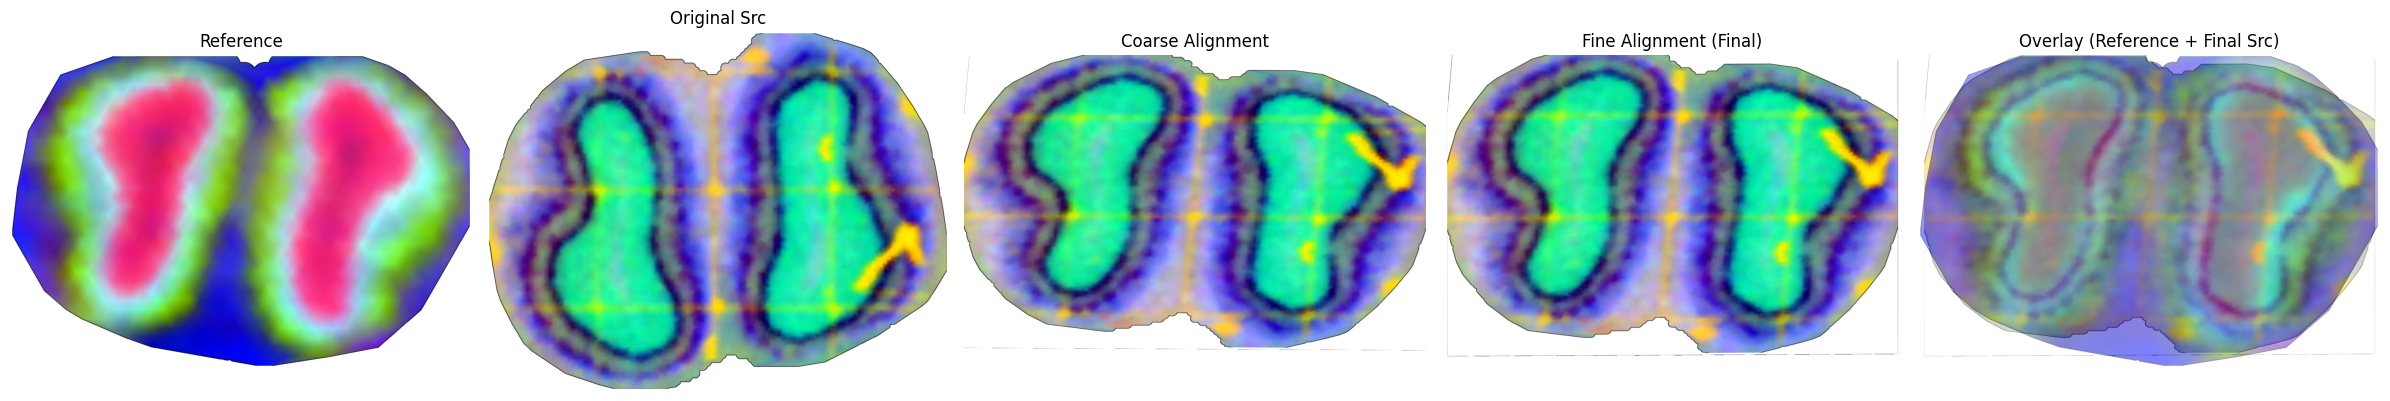

In [7]:
spamoma.align_slices(visualize_correspondences=True)